# RQ2 · Recipe similarity with MinHash and LSH

We evaluate 128-hash signatures on a seeded sample of 5,000 Food.com recipes. Four banding settings propose candidate pairs. We compare those candidates with exact ingredient-set Jaccard at four thresholds.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

candidates = (Path.cwd() / "results", Path.cwd().parent / "results")
results = next((path for path in candidates if (path / "lsh_eval.csv").is_file()), None)
if results is None:
    raise FileNotFoundError(
        "Expected results/lsh_eval.csv near the notebook or repository root."
    )

,bands,rows,threshold,candidates,ground_truth_pairs,true_positives,precision,recall,f1
0,64,2,0.5,1655546,1197,1197,0.0007,1.0000,0.0014
1,64,2,0.7,1655546,33,33,0.0000,1.0000,0.0000
2,64,2,0.8,1655546,12,12,0.0000,1.0000,0.0000
3,64,2,0.9,1655546,1,1,0.0000,1.0000,0.0000
4,32,4,0.5,31886,1197,1107,0.0347,0.9248,0.0669
5,32,4,0.7,31886,33,33,0.0010,1.0000,0.0021
6,32,4,0.8,31886,12,12,0.0004,1.0000,0.0008
7,32,4,0.9,31886,1,1,0.0000,1.0000,0.0001
8,16,8,0.5,863,1197,287,0.3326,0.2398,0.2786
9,16,8,0.7,863,33,28,0.0324,0.8485,0.0625


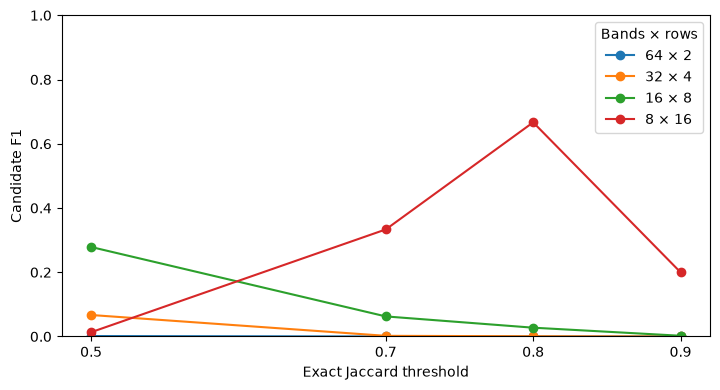

In [ ]:
scores = pd.read_csv(results / "lsh_eval.csv")
latency = pd.read_csv(results / "search_latency.csv")
examples = pd.read_csv(results / "similar_examples.csv")

display(
    scores[
        [
            "bands",
            "rows",
            "threshold",
            "candidates",
            "ground_truth_pairs",
            "true_positives",
            "precision",
            "recall",
            "f1",
        ]
    ].round(4)
)

_, ax = plt.subplots(figsize=(7.3, 4.0))
for (bands, rows), group in scores.groupby(["bands", "rows"], sort=False):
    ax.plot(group["threshold"], group["f1"], marker="o", label=f"{bands} × {rows}")
ax.set(
    xticks=sorted(scores["threshold"].unique()),
    xlabel="Exact Jaccard threshold",
    ylabel="Candidate F1",
    ylim=(0, 1),
)
ax.legend(title="Bands × rows")
plt.tight_layout()
plt.show()

We time top-five retrieval on the same recipe IDs for every method. Queries exclude the input recipe and rank positive matches by exact Jaccard. Index construction is measured separately from query latency.


In [ ]:
def percentile_95(values):
    return values.quantile(0.95)


summary = latency.groupby(["method", "bands", "rows"], dropna=False, sort=False).agg(
    queries=("query_recipe_id", "size"),
    index_build_sec=("index_build_sec", "first"),
    median_ms=("ms_per_query", "median"),
    p95_ms=("ms_per_query", percentile_95),
)
display(summary.round(4))

queries  index_build_sec  median_ms   p95_ms
method bands rows                                              
exact  NaN   NaN       100           0.0000    11.6924  15.9506
lsh    64.0  2.0       100           0.8976     2.2849   6.1122
       32.0  4.0       100           0.6816     0.0843   0.2946
       16.0  8.0       100           0.5357     0.0336   0.0539
       8.0   16.0      100           0.2487     0.0209   0.0456

In [ ]:
display(
    examples.loc[
        examples["rank"].fillna(1).le(2),
        [
            "query_name",
            "method",
            "rank",
            "matched_name",
            "jaccard",
        ],
    ].round(3)
)

,query_name,method,rank,matched_name,jaccard
0,grilled vegetable po boys,lsh,1.0,avocado salsa cheeseburgers,0.148
1,grilled vegetable po boys,lsh,2.0,salsa verde turkey burger,0.130
4,grilled vegetable po boys,exact,1.0,warm mustard potato salad,0.238
5,grilled vegetable po boys,exact,2.0,mushroom burgers ww,0.211
9,tunisian chicken,lsh,NaN,NaN,NaN
10,tunisian chicken,exact,1.0,grilled orange chicken breasts,0.250
11,tunisian chicken,exact,2.0,super bowl party red and white chili crock pot,0.238
15,patty s fresh salsa,lsh,1.0,fresh tomato salsa,0.400
16,patty s fresh salsa,exact,1.0,fresh tomato salsa,0.400
17,patty s fresh salsa,exact,2.0,katie s hot salsa,0.400


Candidate precision includes all pairs emitted by LSH before exact reranking. The latency and score comparisons describe the sampled corpus.
